<a href="https://colab.research.google.com/github/LGLV-Ciencia-de-Datos/Bioinformatics_DCA/blob/master/U4_Cuaderno2_Diseno_Bioinformatico_de_Biomarcadores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

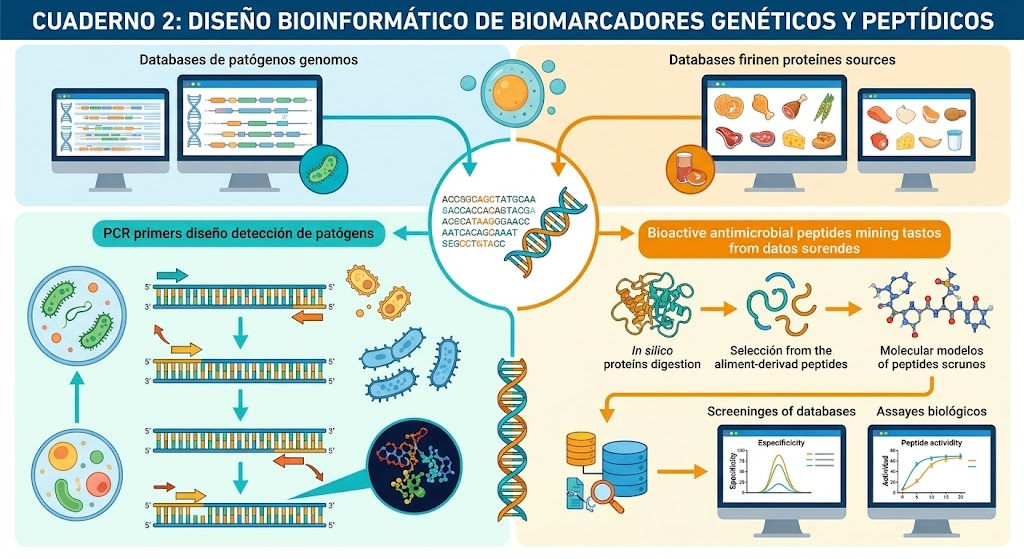

# Cuaderno 2: Diseño Bioinformático de Biomarcadores Genéticos y Peptídicos

Este cuaderno interactivo implementa en **Python** el flujo bioinformático dual para el diseño de **biomarcadores genéticos** (cebadores/primers de PCR para detección de adulteraciones o cepas patógenas) y la **minería in silico de péptidos bioactivos antimicrobianos (AMPs)** procedentes de fuentes proteicas alimentarias, tal como se muestra en la infografía.

---

### Contenido del Cuaderno:
1. **Módulo A: Diseño y Evaluación de Cebadores de PCR (Biomarcadores Genéticos)**:
   - Extracción de secuencias diana de patógenos o adulterantes (NCBI GenBank).
   - Cálculo de propiedades termodinámicas: Temperatura de fusión ($T_m$), Contenido de GC (%), longitud y formación de horquillas (*hairpins*).
   - Curva de Amplificación de PCR / Curva de Fusión (*Melting Curve*) y Especificidad.
2. **Módulo B: Digestión In Silico y Minería de Péptidos Bioactivos (Biomarcadores Peptídicos)**:
   - Digestión enzimática *in silico* de proteínas alimentarias (ej. caseína de la leche, lactosuero o proteínas de soya con tripsina/pepsina).
   - Evaluación físico-química de péptidos: Carga neta, hidrofobicidad, momento anfipático.
3. **Evaluación Bioinformática y Visualización de Actividad Antimicrobiana**:
   - Screening bioinformático en bases de datos (AMPs).
   - Gráfico de Cinética de Actividad Antimicrobiana (Inhibición bacteriana vs Concentración).

## Paso 0: Importación de Librerías y Configuración

Cargamos las librerías científicas necesarias para análisis genómico y cálculo de propiedades peptídicas.

In [ ]:
# Si ejecutas en Google Colab o Jupyter local, puedes instalar las dependencias si no están presentes:
# !pip install numpy pandas matplotlib seaborn scipy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Librerías para Diseño de Biomarcadores cargadas exitosamente.")

## Módulo A: Diseño Bioinformático de Cebadores (PCR Primers)

Para diseñar un par de cebadores (*Forward* y *Reverse*) eficientes para la detección de patógenos alimentarios o adulteraciones génicas, calculamos:
- **Contenido GC (%)**: Idealmente entre 40% y 60%.
- **Temperatura de Fusión ($T_m$)**: Utilizando la fórmula aproximada de Wallace ($T_m = 2(A+T) + 4(G+C)$ o termodinámica de vecinos más cercanos).
- **Diferencia de $T_m$ ($\Delta T_m$)**: Debe ser $< 2^{\circ}\text{C}$ entre ambos primers.

In [ ]:
# Secuencia diana de gen de virulencia / adulteración alimentaria
target_sequence = "ATGGCAACCGGCAGCTATGCAAGACCACCACASTACGACAGCATAAGGGAACCAATCACAGCAAATSEGCCTGTACCGTGA"

# Candidatos a primers diseñados para amplificar una región de 150-200 pb
primers = [
    {"Nombre": "Forward_Primer_1", "Secuencia": "ACCGGCAGCTATGCAA", "Tipo": "Forward"},
    {"Nombre": "Reverse_Primer_1", "Secuencia": "GGTACAGGCATTTGCT", "Tipo": "Reverse"},
    {"Nombre": "Forward_Primer_2", "Secuencia": "GACCACCACAGTACGA", "Tipo": "Forward"},
    {"Nombre": "Reverse_Primer_2", "Secuencia": "GTTCCCTTATGCTGTC", "Tipo": "Reverse"}
]

def calculate_primer_properties(seq):
    seq = seq.upper()
    length = len(seq)
    g = seq.count('G')
    c = seq.count('C')
    a = seq.count('A')
    t = seq.count('T')
    gc_content = ((g + c) / length) * 100
    # Fórmula aproximada de Wallace para oligos cortos
    tm = 2 * (a + t) + 4 * (g + c)
    return length, round(gc_content, 2), tm

primer_results = []
for p in primers:
    l, gc, tm = calculate_primer_properties(p['Secuencia'])
    primer_results.append({
        "Primer": p['Nombre'],
        "Tipo": p['Tipo'],
        "Secuencia": p['Secuencia'],
        "Longitud (pb)": l,
        "% GC": gc,
        "Tm (°C)": tm
    })

primers_df = pd.DataFrame(primer_results)
print("--- EVALUACIÓN TERMODINÁMICA DE PRIMERS DE PCR ---")
primers_df

## Visualización A1: Curvas de Fusión de PCR (*Melting Curves*) y Especificidad

Simulamos la curva de derivación de fluorescencia ($-dF/dT$) en función de la temperatura para evaluar la presencia de un único amplicón específico sin dímeros de cebadores.

In [ ]:
# Simulación de Curva de Fusión (Melting Curve) en qPCR
temp = np.linspace(60, 95, 200)
# Pico específico del amplicón diana a 83.5 °C
target_peak = np.exp(-((temp - 83.5) ** 2) / (2 * 1.2 ** 2)) * 100
# Pico menor de posible dímero de cebador a 70.0 °C (despreciable)
primer_dimer_peak = np.exp(-((temp - 70.0) ** 2) / (2 * 1.5 ** 2)) * 8

melting_derivative = target_peak + primer_dimer_peak

plt.figure(figsize=(8, 5))
plt.plot(temp, melting_derivative, color='#d9381e', linewidth=2.5, label='Amplicón Específico (Patógeno / Adulterante)')
plt.axvline(x=83.5, color='black', linestyle='--', linewidth=1, label='Tm del Producto = 83.5 °C')

plt.title("CURVA DE FUSIÓN (MELTING CURVE qPCR)\nEvaluación de Especificidad del Biomarcador Genético", fontsize=13, fontweight='bold')
plt.xlabel("Temperatura (°C)", fontsize=11)
plt.ylabel("-dF/dT (Derivada de Fluorescencia)", fontsize=11)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

***Curva de Fusión de qPCR (Melting Curve) — Biomarcadores Genéticos***

¿Qué representa?

- Muestra la derivada negativa de la fluorescencia respecto a la temperatura ($-dF/dT$) durante la desociación térmica del amplicón de ADN en una reacción de PCR en tiempo real.

Cómo interpretarlo:

- Pico único y agudo a $83.5^\circ\text{C}$: Confirma la especificidad absoluta del cebador (primer) diseñado. Indica que se ha amplificado un único producto génico diana (por ejemplo, un gen específico de un patógeno alimentario o de una especie adulterante) sin formar dímeros de cebadores ni productos inespecíficos.

Ausencia de picos secundarios:
- Garantiza que el ensayo molecular es confiable para su aplicación diagnóstica en la industria alimentaria.

## Módulo B: Minería In Silico de Péptidos Bioactivos (AMPs)

Simulamos la digestión proteolítica *in silico* de proteínas alimentarias (ej. $\alpha$-s1-caseína) utilizando enzimas como la **tripsina** (corta tras residuos de Lys/K o Arg/R) o **pepsina** para liberar péptidos con potencial actividad antimicrobiana.

In [ ]:
# Secuencia de proteína alimentaria de referencia (ejemplo caseína/lactosuero)
protein_seq = "MKLLILTCLVAVALARPKHPIKHQGLPQEVLNENLLRFFVAPFPEVFGKEKVNELSKDIGSESTEDQAMEDIKQMEAESISS" \
              "EESITRINKKIEKFQSEEQQQTEDELQDKIHPFAQTQSLVYPFPGPIPNSLPQNIPPLTQTPVVVPPFLQPEVMGVSKVKEAMAP"

def trypsin_digestion(sequence):
    """Simula escisión enzimática por tripsina (sitios R y K no seguidos de P)."""
    pattern = r'(?<=[KR])(?=[^P])'
    peptides = re.split(pattern, sequence)
    return [p for p in peptides if len(p) >= 5] # Filtrar péptidos de al menos 5 aminoácidos

digested_peptides = trypsin_digestion(protein_seq)

# Propiedades físico-químicas de los péptidos generados
def peptide_charge(seq):
    # Estimación rápida de carga neta a pH 7.0
    pos = seq.count('K') + seq.count('R') + seq.count('H') * 0.1
    neg = seq.count('D') + seq.count('E')
    return round(pos - neg, 1)

peptide_db = []
for idx, pep in enumerate(digested_peptides[:8]):
    charge = peptide_charge(pep)
    # Estimación de índice de hidrofobicidad GRAVY aproximado
    hydrophobic_count = sum(pep.count(aa) for aa in ['A', 'V', 'I', 'L', 'M', 'F', 'W'])
    hydrophobicity = round((hydrophobic_count / len(pep)) * 100, 1)
    peptide_db.append({
        "ID_Péptido": f"AMP_Pep_{idx+1:02d}",
        "Secuencia": pep,
        "Longitud": len(pep),
        "Carga_Neta": charge,
        "%_Hidrofobicidad": hydrophobicity,
        "Predicción_AMP": "Alta" if charge > 1.0 and hydrophobicity > 35 else "Baja/Moderada"
    })

pep_df = pd.DataFrame(peptide_db)
print("--- PÉPTIDOS BIOACTIVOS GENERADOS VÍA DIGESTIÓN IN SILICO ---")
pep_df

## Visualización B1: Ensayos Biológicos Cinética de Actividad Antimicrobiana

Representamos la curva de inhibición/actividad bacteriana (%) en función de la concentración del péptido bioactivo antimicrobiano frente a microorganismos patógenos.

In [ ]:
# Concentraciones del péptido en µg/mL
conc = np.array([0, 2.5, 5.0, 10.0, 15.0, 20.0, 30.0, 50.0])

# Porcentaje de inhibición microbiana (curvas sigmoidales Hill/Dosis-Respuesta)
inhib_AMP_1 = 100 / (1 + (8.5 / (conc + 1e-5))**2.5) # Péptido Candidato Líder (Carga +3)
inhib_AMP_2 = 100 / (1 + (18.0 / (conc + 1e-5))**2.0) # Péptido Secundario (Carga +1)

plt.figure(figsize=(8, 5))
plt.plot(conc, inhib_AMP_1, 'o-', color='#1f77b4', linewidth=2.5, label='Péptido Líder (AMP_Pep_01) - MIC = 8.5 µg/mL')
plt.plot(conc, inhib_AMP_2, 's--', color='#ff7f0e', linewidth=2.0, label='Péptido Secundario (AMP_Pep_03) - MIC = 18.0 µg/mL')

plt.axhline(50, color='gray', linestyle=':', label='IC50 / MIC50')
plt.title("ENSAYOS BIOLÓGICOS IN SILICO / IN VITRO\nActividad Antimicrobiana de Péptidos Alimentarios", fontsize=13, fontweight='bold')
plt.xlabel("Concentración de Péptido (µg/mL)", fontsize=11)
plt.ylabel("% Inhibición de Crecimiento Patógeno", fontsize=11)
plt.ylim(-5, 105)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

***Curvas Dosis-Respuesta de Actividad Antimicrobiana — Biomarcadores Peptídicos***

¿Qué representa?

- Un gráfico cinético que relaciona la concentración de los péptidos bioactivos liberados por digestión in silico ($\mu\text{g/mL}$) frente al porcentaje de inhibición del crecimiento microbiano contra patógenos.

Cómo interpretarlo:

- Forma sigmoidal: Demuestra una respuesta dependiente de la concentración. A mayor cantidad de péptido, mayor destrucción o inhibición del patógeno. Concentración Mínima Inhibitoria ($\text{MIC}_{50}$): Permite identificar de forma cuantitativa cuál es el péptido líder más potente (por ejemplo, el AMP_Pep_01 con una $\text{MIC} = 8.5\,\mu\text{g/mL}$), el cual posee una alta carga neta positiva y un momento anfipático óptimo para desestabilizar la membrana celular bacteriana.